# Avance 2: Exploración de los datos y regresión lineal múltiple

Proyecto: determinantes de las hospitalizaciones prolongadas en beneficiarios FONASA (Chile, 2020)

**Resumen.** Con los mismos 968.098 egresos FONASA de 2020 del Avance 1, ajustamos una regresión lineal múltiple de ln(días de estada) con las 7 variables que eligió el BIC. La entrenamos con 677.669 egresos (70 %) y la evaluamos con 290.429 (30 %):

- El modelo explica el 19,8 % de la variabilidad de ln(días), tanto en entrenamiento como en test (R² ajustado = 0,198 en los dos). No hay sobreajuste.
- El capítulo CIE-10 es el factor más asociado con la duración: frente a las enfermedades del aparato digestivo (K00-K93), la mediana de días de los trastornos mentales (F00-F99) es 213 % mayor y la de las enfermedades del ojo (H00-H59), 32 % menor (con lo demás constante; más precisamente, es un cambio en la media geométrica de los días).
- Con el diagnóstico y el resto controlados, la mediana de días de los egresos de establecimientos del SNSS es 69,7 % mayor que la de fuera del SNSS, la de los hombres 11,4 % mayor que la de las mujeres, y cada año de edad se asocia con una mediana 0,9 % mayor.
- Relevancia con el mismo criterio del Avance 1 (significativo y efecto al menos pequeño, f² ≥ 0,02; Cohen, 1988): el f² parcial es 0,0798 para el capítulo, 0,0424 para el establecimiento y 0,0365 para la edad, los tres con efecto pequeño. Región (0,0048), sexo (0,0026), condición de egreso (0,0002) y cirugía (0,0002) son significativos pero quedan bajo el umbral, así que no los consideramos relevantes. Ningún factor llega solo a un efecto mediano (0,15); el bloque clínico completo sí (f² = 0,1526).
- Cirugía (−2,7 %) y condición de egreso (+6,5 %) se achican mucho respecto de los resultados de a pares del Avance 1.
- En días, el modelo reduce el RMSE de 12,71 a 12,23 respecto de predecir la media, pero con el factor de Duan el MAE no mejora (5,36 contra 5,03 de predecir la mediana); sin Duan baja a 4,67 y sí supera a la mediana. Duan corrige la media, que es lo que mide el RMSE y lo que sirve para planificar los días-cama totales. La predicción sin corregir se acerca a la mediana condicional, que es lo que premia el MAE (3.4).
- Este avance responde la parte de la duración. Las estadías prolongadas (más de 15 días) se respondieron en el Avance 1 solo de a pares, y aquí no hay un modelo multivariable para ellas (1 y 4.5).
- Los errores tienen varianza no constante (Breusch-Pagan), así que los errores estándar son HC3.

## 1. Pregunta de investigación e hipótesis

La pregunta y las hipótesis son las del Avance 1.

> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía y con las estadías prolongadas (más de 15 días) en los egresos FONASA de Chile en 2020?

**Hipótesis general**

- H₀: la duración de la estadía y la ocurrencia de estadías prolongadas no se asocian con los factores clínicos, demográficos ni del sistema de salud.
- H₁: al menos uno de esos factores se asocia con la duración de la estadía o con la ocurrencia de estadías prolongadas.

Hipótesis específicas, una por grupo de factores:

| | Factores | H₁ |
|---|---|---|
| H1a | Clínicos: capítulo del diagnóstico (CIE-10), cirugía y condición de egreso | Se asocian a la duración y a la estadía prolongada |
| H1b | Demográficos: edad, sexo, nacionalidad y etnia | Se asocian a la duración y a la estadía prolongada (esperamos más días a mayor edad) |
| H1c | Sistema de salud: tipo de establecimiento y región | Se asocian a la duración y a la estadía prolongada |

Qué cambia en este avance: el Avance 1 comparó los factores de a pares. Aquí los metemos todos juntos en un modelo de ln(días) con las 7 variables que eligió el BIC (capítulo, cirugía, condición de egreso, edad, sexo, establecimiento y región), para ver cuánto se asocia cada uno con la duración cuando se controla por los demás. Nacionalidad y etnia quedaron fuera por el BIC en la sección 5.6 del Avance 1. La pregunta y las hipótesis tienen dos partes y las respondemos por separado. La duración la responde este avance con el modelo conjunto. La estadía prolongada (Sí/No) se respondió en el Avance 1 solo de a pares, con chi-cuadrado y V de Cramér (5.4). El Avance 1 propuso únicamente la regresión lineal de ln(días) y dejó fuera la logística, así que aquí no ajustamos ningún modelo multivariable para las prolongadas. Eso queda como limitación y como trabajo para el paper. La relevancia de cada factor la juzgamos con el mismo criterio del Avance 1: significativo y con un efecto al menos pequeño según Cohen (1988), que aquí medimos con f² (sección 3.2).

## 2. Exploración y preparación de los datos

El curso propone cinco etapas: análisis descriptivo, ajuste de variables, valores nulos, valores atípicos y relación entre variables. Las seguimos en ese orden. Primero cargamos los datos con el mismo código del Avance 1.

### Paso 1: cargar los datos

Solo FONASA (`PREVISION = 1`) y estadías de hasta 365 días. Los 397 egresos de más de un año los tratamos como errores de registro, igual que en el Avance 1. Los atípicos de Tukey entre 15 y 365 días sí los conservamos, porque son estadías reales (etapa 4).

In [1]:
import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
teal, petroleo, coral = "#0E7C7A", "#0F2A33", "#D9534F"

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
print("Egresos 2020:", len(df))

df = df[df["PREVISION"] == "1"]                      # solo FONASA
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
bruta = df["dias_estada"].copy()                     # con los de más de 365 días, para compararlos en la etapa 4
print("Estadías de más de 365 días:", (df["dias_estada"] > 365).sum(), "| máximo:", df["dias_estada"].max(), "días")
df = df[df["dias_estada"] <= 365].copy()             # quitamos errores de registro
print("Egresos FONASA con estada <= 365 días:", len(df))


Egresos 2020: 1330477


Estadías de más de 365 días: 397 | máximo: 16598 días
Egresos FONASA con estada <= 365 días: 968098


Quedan 968.098 egresos, el mismo número del Avance 1.

### Paso 2: construir las variables

Reutilizamos los mapeos del Avance 1: la edad es el punto medio de cada tramo, el capítulo CIE-10 viene del diccionario del DEIS, `INTERV_Q` 1/2 es cirugía Sí/No y `CONDICION_EGRESO` 1/2 es vivo/fallecido. Nos quedamos solo con la respuesta, los 7 predictores y `DIAG2` (para revisar sus nulos), y agregamos ln(días).

In [2]:
edad_media = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()

df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["tramo_edad"] = df["GRUPO_EDAD"]
df["sexo"] = df["SEXO"]
df["capitulo"] = df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
df["fallecido"] = df["CONDICION_EGRESO"].map({"1": "No", "2": "Sí"})
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"]
df["log_dias"] = np.log(df["dias_estada"])

variables = ["dias_estada", "log_dias", "prolongada", "edad", "tramo_edad", "sexo", "capitulo", "cirugia",
             "fallecido", "establecimiento", "region", "DIAG2"]
df = df[variables]
print("Egresos:", len(df), "| columnas:", df.shape[1])
df.head()


Egresos: 968098 | columnas: 12


,dias_estada,log_dias,prolongada,edad,tramo_edad,sexo,capitulo,cirugia,fallecido,establecimiento,region,DIAG2
0,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,NaN
1,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,NaN
2,1,0.0,No,5.0,1 a 9,HOMBRE,Z00-Z99,Sí,No,No SNSS,De Tarapacá,NaN
3,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,NaN
4,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,NaN


### Etapa 1: análisis descriptivo

In [3]:
cols = ["dias_estada", "log_dias", "edad"]
desc = df[cols].agg(["count", "mean", "median"]).T
desc["Q1"] = df[cols].quantile(0.25)
desc["Q3"] = df[cols].quantile(0.75)
desc["RIC"] = desc["Q3"] - desc["Q1"]
desc["s"] = df[cols].std()
desc["CV"] = desc["s"] / desc["mean"]
desc["asimetría"] = df[cols].skew()
desc.round(2)


,count,mean,median,Q1,Q3,RIC,s,CV,asimetría
dias_estada,968098.0,6.70,3.0,2.00,7.00,5.00,12.79,1.91,9.04
log_dias,968098.0,1.25,1.1,0.69,1.95,1.25,1.04,0.83,0.68
edad,968098.0,45.01,44.5,24.50,64.50,40.00,24.29,0.54,0.01


Los días de estada tienen media 6,70 y mediana 3, con Q1 = 2 y Q3 = 7 (RIC = 5). La desviación estándar (12,79) es casi el doble de la media (CV = 1,91) y la asimetría es 9,04: la mayoría de los egresos dura pocos días y unos pocos duran muchísimo. En ln(días) la asimetría baja a 0,68 y la media (1,25) queda cerca de la mediana (1,10), por eso modelamos el logaritmo. La edad es simétrica (asimetría 0,01; media 45,01 y mediana 44,5), con Q1 = 24,5 y Q3 = 64,5.

In [4]:
for var in ["establecimiento", "sexo"]:
    print((100 * df[var].value_counts(normalize=True)).round(1).to_string(), "\n")
cap = 100 * df["capitulo"].value_counts(normalize=True)
print("Capítulos más frecuentes (%):")
print(cap.head(6).round(1).to_string())
print(f"Los otros {len(cap) - 6} capítulos juntos:", round(cap.iloc[6:].sum(), 1), "%")


establecimiento
SNSS       81.8
No SNSS    18.2 

sexo
MUJER     60.0
HOMBRE    40.0 

Capítulos más frecuentes (%):
capitulo
O00-O99    20.4
K00-K93    13.8
S00-T98     9.8
I00-I99     9.3
N00-N99     7.6
C00-D48     7.4
Los otros 15 capítulos juntos: 31.7 %


El 81,8 % de los egresos son de establecimientos del SNSS y el 60,0 % son mujeres. El capítulo más frecuente es el de embarazo, parto y puerperio (O00-O99, 20,4 %), seguido por el digestivo (K00-K93, 13,8 %) y los traumatismos (S00-T98, 9,8 %). Los otros 15 capítulos suman el 31,7 %.

**Figura 1.** Distribución de los días de estada (izquierda, recortada a 60 días), de ln(días) (centro) y curva de concentración de los días-cama (derecha).

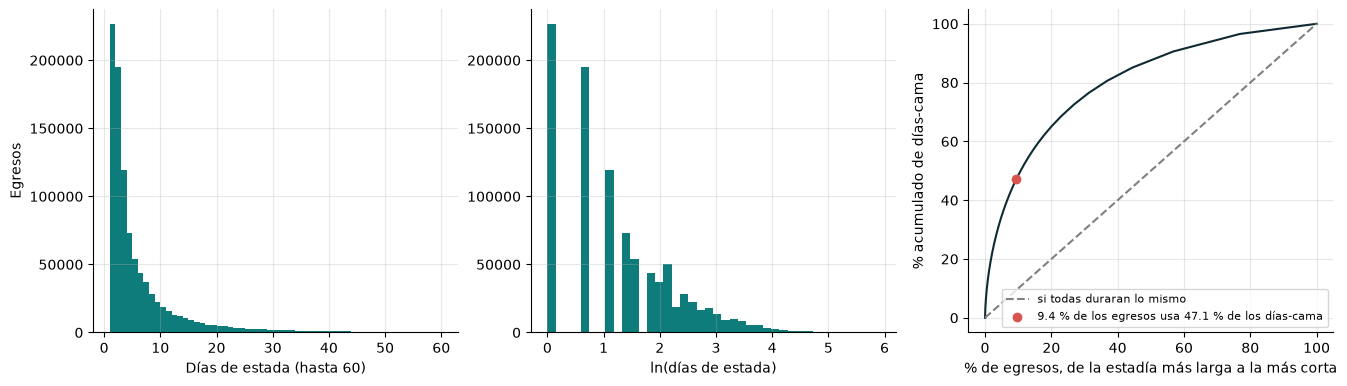

Media: 6.7 | mediana: 3.0 | egresos prolongados: 9.4 % | días-cama que usan: 47.1 %


In [5]:
largas = df["prolongada"] == "Sí"
pct_egresos = 100 * largas.mean()
pct_dias = 100 * df.loc[largas, "dias_estada"].sum() / df["dias_estada"].sum()

orden = np.sort(df["dias_estada"].values)[::-1]                 # de la estadía más larga a la más corta
x_conc = 100 * np.arange(1, len(orden) + 1) / len(orden)
y_conc = 100 * orden.cumsum() / orden.sum()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(df["dias_estada"], bins=range(1, 61), color=teal)
ax[0].set_xlabel("Días de estada (hasta 60)")
ax[0].set_ylabel("Egresos")
ax[1].hist(df["log_dias"], bins=40, color=teal)
ax[1].set_xlabel("ln(días de estada)")
ax[2].plot(x_conc[::500], y_conc[::500], color=petroleo)
ax[2].plot([0, 100], [0, 100], color="gray", linestyle="--", label="si todas duraran lo mismo")
ax[2].scatter([pct_egresos], [pct_dias], color=coral, zorder=3,
              label=f"{pct_egresos:.1f} % de los egresos usa {pct_dias:.1f} % de los días-cama")
ax[2].set_xlabel("% de egresos, de la estadía más larga a la más corta")
ax[2].set_ylabel("% acumulado de días-cama")
ax[2].legend(loc="lower right", fontsize=8)
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/avance2_distribucion.png", dpi=200, bbox_inches="tight")
plt.show()
print("Media:", round(df["dias_estada"].mean(), 1), "| mediana:", df["dias_estada"].median(),
      "| egresos prolongados:", round(pct_egresos, 1), "% | días-cama que usan:", round(pct_dias, 1), "%")


El histograma de días muestra la cola larga: la moda es 1 día (226.248 egresos), seguida de 2 días (194.873) y 3 días (119.440), y la frecuencia cae rápido. En ln(días) las barras están separadas porque los días son enteros (ln 1 = 0, ln 2 = 0,69, ln 3 = 1,10), y la forma queda menos asimétrica, con una cola derecha más corta. La curva de la derecha ordena los egresos de la estadía más larga a la más corta: el 9,4 % de los egresos con más de 15 días usa el 47,1 % de los días-cama de estos egresos FONASA (estadías de hasta 365 días). Para la gestión de camas, esos pocos egresos largos usan casi tantos días-cama como todos los demás juntos, y queremos entender qué se asocia con la duración.

### Etapa 2: ajuste de variables

| Variable | Tipo | Codificación | Referencia |
|---|---|---|---|
| ln(días) | Numérica, respuesta | Logaritmo natural de `DIAS_ESTADA` | |
| Edad | Numérica | `edad_c` = punto medio del tramo − media, y `edad_c`² | Edad media (0) |
| Capítulo CIE-10 | Categórica (21) | 20 indicadoras | K00-K93 |
| Cirugía | Categórica | Indicadora de Sí | No |
| Condición de egreso | Categórica | Indicadora de fallecido | Vivo |
| Sexo | Categórica | Indicadora de hombre | Mujer |
| Establecimiento | Categórica | Indicadora de SNSS | No SNSS |
| Región | Categórica (16) | 15 indicadoras | Metropolitana de Santiago |

En el Avance 1 centramos la edad en 50 para que edad y edad² no quedaran colineales en la selección por BIC. Aquí la centramos en su media, para que el intercepto corresponda a un paciente de edad promedio. Es solo un cambio de origen y da el mismo ajuste.

En sexo tomamos como referencia a la mujer para expresar el coeficiente como hombres frente a mujeres. Así respondemos la pregunta que el Avance 1 dejó pendiente: si la diferencia entre hombres y mujeres se mantiene al controlar por diagnóstico. La respondemos en 3.3: se mantiene (+11,4 %). Cambiar la referencia no altera el ajuste, solo el signo y la lectura del coeficiente.

Como capítulo de referencia usamos K00-K93 en vez de O00-O99, que usamos en el Avance 1 solo para la selección. O00-O99 es solo de mujeres, y con ella de referencia el coeficiente de sexo se mezclaría con el del capítulo. K00-K93 es el segundo capítulo más frecuente, con hombres y mujeres, y tiene una mediana baja (2 días), lo que deja los demás coeficientes como diferencias respecto de un egreso corto y habitual.

In [6]:
edad_prom = df["edad"].mean()
df["edad_c"] = df["edad"] - edad_prom
print("Edad media (el cero de edad_c):", round(edad_prom, 2))
k = df[df["capitulo"] == "K00-K93"]
print("Capítulo K00-K93:", round(100 * len(k) / len(df), 1), "% de los egresos | mediana:", k["dias_estada"].median(),
      "días | sexo (% mujeres):", round(100 * (k["sexo"] == "MUJER").mean(), 1))
print("Valores de sexo:", sorted(df["sexo"].unique()))


Edad media (el cero de edad_c): 45.01
Capítulo K00-K93: 13.8 % de los egresos | mediana: 2.0 días | sexo (% mujeres): 53.6
Valores de sexo: ['HOMBRE', 'MUJER']


La edad media es 45,01 años. K00-K93 es el 13,8 % de los egresos, con una mediana de 2 días y un 53,6 % de mujeres, así que sirve como referencia sin confundir el sexo.

### Etapa 3: valores nulos

In [7]:
usadas = ["dias_estada", "edad", "sexo", "capitulo", "cirugia", "fallecido", "establecimiento", "region", "DIAG2"]
print(df[usadas].isna().sum().to_string())
pct_diag2 = 100 * df["DIAG2"].isna().mean()
print("DIAG2 nulo:", round(pct_diag2, 1), "% de los egresos")


dias_estada             0
edad                    0
sexo                    0
capitulo                0
cirugia                 0
fallecido               0
establecimiento         0
region                  0
DIAG2              872823
DIAG2 nulo: 90.2 % de los egresos


Las variables de la respuesta y de los 7 predictores no tienen ningún nulo, así que no hubo que imputar ni eliminar egresos. `DIAG2` tiene un 90,2 % de nulos. En el Avance 1 comprobamos que solo aparece en el capítulo S00-T98, con una V de Cramér de 1,00, es decir, que repite información del capítulo. Por eso descartamos la columna y no la imputamos.

### Etapa 4: valores atípicos

Usamos dos criterios: el de Tukey (Ls = Q3 + 1,5·RIC) y el de |z| > 3. Los aplicamos a los días y a ln(días). Además comparamos media y desviación estándar con mediana y MAD (la mediana de las desviaciones absolutas respecto de la mediana), antes y después del filtro de 365 días.

In [8]:
filas = []
for nombre, x in [("días", df["dias_estada"]), ("ln(días)", df["log_dias"])]:
    q1, q3 = x.quantile([0.25, 0.75])
    li, ls = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    z = (x - x.mean()) / x.std()
    filas.append({"variable": nombre, "Li": li, "Ls": ls, "n > Ls": (x > ls).sum(), "% > Ls": 100 * (x > ls).mean(),
                  "n < Li": (x < li).sum(), "n |z| > 3": (z.abs() > 3).sum(), "% |z| > 3": 100 * (z.abs() > 3).mean()})
atip = pd.DataFrame(filas).set_index("variable")
print(atip.round(2).to_string())

comp = pd.DataFrame({"n": [len(bruta), len(df), len(df)]}, index=["días con > 365 incluidos", "días (base final)", "ln(días)"])
series = [bruta, df["dias_estada"], df["log_dias"]]
comp["media"] = [x.mean() for x in series]
comp["s"] = [x.std() for x in series]
comp["mediana"] = [x.median() for x in series]
comp["MAD"] = [(x - x.median()).abs().median() for x in series]
comp.round(2)


            Li     Ls  n > Ls  % > Ls  n < Li  n |z| > 3  % |z| > 3
variable                                                           
días     -5.50  14.50   99978   10.33       0      14614       1.51
ln(días) -1.19   3.83   14614    1.51       0       4745       0.49


,n,media,s,mediana,MAD
días con > 365 incluidos,968495,7.29,59.74,3.0,2.00
días (base final),968098,6.70,12.79,3.0,2.00
ln(días),968098,1.25,1.04,1.1,0.69


Con Tukey el límite superior de los días es 14,5, y lo superan 99.978 egresos (10,33 %). Con |z| > 3 son 14.614 (1,51 %). En ln(días) el límite sube a 3,83 (unos 46 días) y lo superan 14.614 egresos (1,51 %); con |z| > 3 son 4.745 (0,49 %). Por abajo no hay ninguno, porque el mínimo es 1 día. Que en ln(días) siga habiendo atípicos según Tukey se explica porque la cola derecha sigue siendo más larga que la izquierda.

En la comparación se ve por qué filtramos los 397 egresos de más de 365 días: con ellos la media sube de 6,70 a 7,29 y la desviación estándar de 12,79 a 59,74, mientras que la mediana (3) y el MAD (2) no cambian. Un puñado de registros imposibles mueve a la media y a s, pero no a las medidas basadas en la mediana.

**Figura 2.** Diagrama de caja de los días de estada (izquierda) y de ln(días) (derecha). La línea roja marca Q3 + 1,5·RIC.

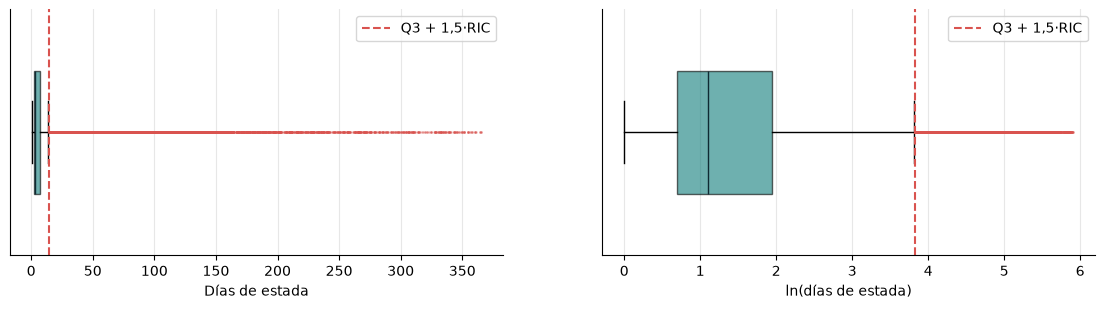

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
for a, col, titulo in zip(ax, ["dias_estada", "log_dias"], ["Días de estada", "ln(días de estada)"]):
    a.boxplot(df[col], orientation="horizontal", widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo),
              flierprops=dict(marker=".", markersize=2, markerfacecolor=coral, markeredgecolor=coral, alpha=0.3))
    a.axvline(atip.loc["días" if col == "dias_estada" else "ln(días)", "Ls"], color=coral, linestyle="--", label="Q3 + 1,5·RIC")
    a.set_xlabel(titulo)
    a.set_yticks([])
    a.legend()
fig.savefig("figures/avance2_atipicos.png", dpi=200, bbox_inches="tight")
plt.show()


En días, la caja está pegada a la izquierda y los puntos rojos se extienden hasta 365 días, el máximo que dejamos. En ln(días) la caja es simétrica y los puntos pasan a ser una cola más corta. Decidimos conservar estos egresos, que van de 15 a 365 días. Los más de 365 días los excluimos porque son errores de registro (el máximo es de 16.598 días, unos 45 años). Estos otros son estadías reales y son el fenómeno que queremos estudiar: las estadías largas son las que más días-cama usan, y quitarlas dejaría un modelo que no sirve para lo que nos importa. Lo que sí hacemos es modelar ln(días), que reduce su influencia sobre los coeficientes, y usar errores estándar HC3, que no suponen varianza constante (sección 3.3).

### Etapa 5: relación entre variables

Para ver si los predictores categóricos se repiten entre sí, calculamos la V de Cramér entre todos los pares. La edad queda fuera porque es numérica.

capitulo  cirugia            0.429
          sexo               0.428
cirugia   establecimiento    0.283
capitulo  fallecido          0.261
          establecimiento    0.190
% de egresos con cirugía por capítulo: mínimo 0.7 (F00-F99), máximo 75.0 (M00-M99)
% de mujeres en O00-O99: 100.0


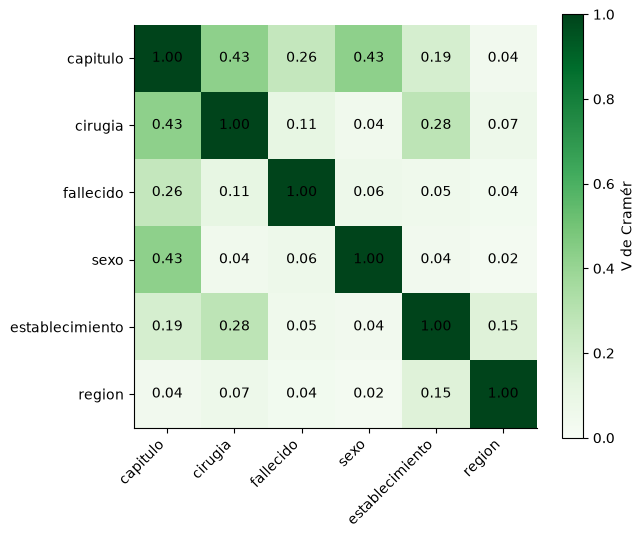

In [10]:
cats = ["capitulo", "cirugia", "fallecido", "sexo", "establecimiento", "region"]
V = pd.DataFrame(1.0, index=cats, columns=cats)
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        tabla = pd.crosstab(df[a], df[b])
        chi2 = stats.chi2_contingency(tabla)[0]
        V.loc[a, b] = V.loc[b, a] = np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1)))

pares = V.where(~np.eye(len(cats), dtype=bool)).stack()
pares = pares[[a < b for a, b in pares.index]].sort_values(ascending=False)
print(pares.round(3).head(5).to_string())
cir = 100 * df.groupby("capitulo")["cirugia"].apply(lambda s: (s == "Sí").mean())
print("% de egresos con cirugía por capítulo: mínimo", round(cir.min(), 1), "(" + cir.idxmin() + "), máximo", round(cir.max(), 1), "(" + cir.idxmax() + ")")
print("% de mujeres en O00-O99:", round(100 * (df.loc[df["capitulo"] == "O00-O99", "sexo"] == "MUJER").mean(), 1))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(V, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(cats)), cats, rotation=45, ha="right")
ax.set_yticks(range(len(cats)), cats)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, f"{V.iloc[i, j]:.2f}", ha="center", va="center", color="black")
ax.grid(False)
fig.colorbar(im, label="V de Cramér")
fig.savefig("figures/avance2_cramer.png", dpi=200, bbox_inches="tight")
plt.show()


**Figura 3.** V de Cramér entre los predictores categóricos.

El máximo es 0,43 entre capítulo y cirugía, seguido de capítulo y sexo (0,43) y cirugía y establecimiento (0,28). Es una asociación mediana según Cohen (1988) (V entre 0,3 y 0,5, con una de las dos variables de dos categorías) y tiene sentido: la proporción de egresos con cirugía va de 0,7 % (F00-F99) a 75,0 % (M00-M99), y el capítulo O00-O99 es solo de mujeres. No llega a una redundancia como la de `DIAG2`, y lo confirmamos con el VIF en 3.6. Mantenemos las tres variables.

Ahora separamos los datos: el 70 % para entrenar (`df.sample(frac=0.7, random_state=1)`) y el resto para evaluar.

In [11]:
train = df.sample(frac=0.7, random_state=1).copy()
test = df.drop(train.index).copy()
balance = pd.DataFrame({
    "egresos": [len(train), len(test)],
    "media de días": [d["dias_estada"].mean() for d in (train, test)],
    "mediana de días": [d["dias_estada"].median() for d in (train, test)],
    "% prolongadas": [100 * (d["prolongada"] == "Sí").mean() for d in (train, test)],
    "% SNSS": [100 * (d["establecimiento"] == "SNSS").mean() for d in (train, test)],
    "% fallecidos": [100 * (d["fallecido"] == "Sí").mean() for d in (train, test)],
    "edad media": [d["edad"].mean() for d in (train, test)],
}, index=["train", "test"])
balance.round(2)


,egresos,media de días,mediana de días,% prolongadas,% SNSS,% fallecidos,edad media
train,677669,6.71,3.0,9.40,81.84,3.84,45.01
test,290429,6.69,3.0,9.37,81.86,3.89,45.02


Entrenamiento y test quedan casi iguales en la media de días (6,71 y 6,69), en el porcentaje de estadías prolongadas (9,40 % y 9,37 %), en el de SNSS (81,84 % y 81,86 %), en el de fallecidos (3,84 % y 3,89 %) y en la edad media (45,01 y 45,02). Por lo tanto una diferencia entre las métricas de entrenamiento y de test no se podría atribuir a que las muestras sean distintas.

## 3. Resultados y modelamiento

### 3.1 Modelo propuesto en el Avance 1

Proponíamos una regresión lineal múltiple de ln(días) con 7 variables explicativas, evaluada con R² ajustado, MAE y RMSE sobre un 30 % de test:

$$\ln(\text{días}_i) = \beta_0 + \sum_{c}\gamma_c\,\text{capítulo}_{ic} + \beta_1\,\text{cirugía}_i + \beta_2\,\text{fallecido}_i + \beta_3\,\text{edad}_{c,i} + \beta_4\,\text{edad}_{c,i}^2 + \beta_5\,\text{hombre}_i + \beta_6\,\text{SNSS}_i + \sum_{r}\delta_r\,\text{región}_{ir} + \varepsilon_i$$

Como la respuesta está en logaritmo, un coeficiente β multiplica por e^β la mediana de los días (más precisamente, su media geométrica, que no es la media), es decir, un cambio porcentual de %Δ = 100·(e^β − 1), manteniendo constante todo lo demás. Por eso cada %Δ que damos es una diferencia en la mediana de días a igual valor del resto de las variables, y no en la media. Es el mismo modelo con el que cerramos el Avance 1, ahora con los capítulos referidos a K00-K93.

### 3.2 Modelos anidados

Para ver cuánto aporta cada bloque de variables, ajustamos cuatro modelos anidados con los datos de entrenamiento: M0 (solo el intercepto), M1 (bloque clínico: capítulo, cirugía y condición de egreso), M2 (M1 más edad, edad² y sexo) y M3 (M2 más establecimiento y región, que es el modelo propuesto). El F parcial compara cada modelo con el anterior.

In [12]:
cap = "C(capitulo, Treatment('K00-K93'))"
reg = "C(region, Treatment('Metropolitana de Santiago'))"
f1 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido)"
f2 = f1 + " + edad_c + I(edad_c**2) + C(sexo, Treatment('MUJER'))"
f3 = f2 + f" + C(establecimiento) + {reg}"
modelos = [smf.ols(f, train).fit() for f in ["log_dias ~ 1", f1, f2, f3]]
m3 = modelos[3]

filas = []
for i, m in enumerate(modelos):
    fila = {"modelo": f"M{i}", "k": int(m.df_model) + 1, "R²": m.rsquared, "R² aj.": m.rsquared_adj, "BIC": m.bic}
    if i > 0:
        fila["f² Cohen"] = (m.rsquared - modelos[i - 1].rsquared) / (1 - m.rsquared)   # f² = (R² completo − R² reducido) / (1 − R² completo)
        a = anova_lm(modelos[i - 1], m)
        fila.update({"Δ BIC": m.bic - modelos[i - 1].bic, "F parcial": a["F"].iloc[1],
                     "gl": int(a["df_diff"].iloc[1]), "valor-p": a["Pr(>F)"].iloc[1]})
    filas.append(fila)
tabla_modelos = pd.DataFrame(filas).set_index("modelo")
tabla_modelos["BIC"] = tabla_modelos["BIC"].round(0)
tabla_modelos["Δ BIC"] = tabla_modelos["Δ BIC"].round(0)
tabla_modelos.round(4) + 0


,k,R²,R² aj.,BIC,f² Cohen,Δ BIC,F parcial,gl,valor-p
modelo,,,,,,,,,
M0,1,0.0000,0.0000,1970021.0,NaN,NaN,NaN,NaN,NaN
M1,23,0.1324,0.1323,1874093.0,0.1526,-95928.0,4699.4019,22.0,0.0
M2,26,0.1622,0.1621,1850461.0,0.0355,-23632.0,8029.8778,3.0,0.0
M3,42,0.1981,0.1981,1820927.0,0.0449,-29534.0,1900.5908,16.0,0.0


Cada bloque mejora el modelo. El bloque clínico (M1) hace lo más grande: lleva el R² ajustado de 0 a 0,132 y baja el BIC en 95.928. Edad y sexo (M2) lo suben a 0,162 (BIC −23.632) y establecimiento y región (M3) a 0,198 (BIC −29.534). Todos los F parciales tienen p < 0,001 y el BIC sigue bajando, así que ningún bloque sobra. Aun así, M3 deja sin explicar cerca del 80 % de la variabilidad de ln(días). Una explicación probable, que no probamos, es que la base no trae variables de gravedad ni el peso GRD. La columna f² Cohen es el tamaño del efecto de cada bloque, que interpretamos a continuación.

In [13]:
def cohen(f2):                                    # umbrales de Cohen (1988) para f²
    return "grande" if f2 >= 0.35 else "mediano" if f2 >= 0.15 else "pequeño" if f2 >= 0.02 else "menor que pequeño"

r2_3 = m3.rsquared
bloques = pd.DataFrame({"comparación": ["M1 frente a M0 (clínico)", "M2 frente a M1 (edad y sexo)", "M3 frente a M2 (establecimiento y región)", "M3 frente a M0 (modelo completo)"],
                        "f²": [(modelos[j].rsquared - modelos[k0].rsquared) / (1 - modelos[j].rsquared) for j, k0 in [(1, 0), (2, 1), (3, 2), (3, 0)]]})
bloques["efecto (Cohen)"] = bloques["f²"].map(cohen)

# f² parcial de cada factor: lo quitamos de M3 (ajuste OLS en entrenamiento) y vemos cuánto baja el R²
terminos = {"capítulo": cap, "cirugía": "C(cirugia)", "fallecido": "C(fallecido)", "edad (edad y edad²)": "edad_c + I(edad_c**2)",
            "sexo": "C(sexo, Treatment('MUJER'))", "establecimiento": "C(establecimiento)", "región": reg}
filas = []
for nombre in terminos:
    sin = smf.ols("log_dias ~ " + " + ".join(t for n, t in terminos.items() if n != nombre), train).fit()
    filas.append({"factor": nombre, "R² sin el factor": sin.rsquared, "f² parcial": (r2_3 - sin.rsquared) / (1 - r2_3)})
parciales = pd.DataFrame(filas).set_index("factor")
parciales["efecto (Cohen)"] = parciales["f² parcial"].map(cohen)
print("R² de M3:", round(r2_3, 4))
print(bloques.round(4).to_string(index=False), "\n")
print(parciales.sort_values("f² parcial", ascending=False).round(4).to_string())


R² de M3: 0.1981
                              comparación     f² efecto (Cohen)
                 M1 frente a M0 (clínico) 0.1526        mediano
             M2 frente a M1 (edad y sexo) 0.0355        pequeño
M3 frente a M2 (establecimiento y región) 0.0449        pequeño
         M3 frente a M0 (modelo completo) 0.2471        mediano 

                     R² sin el factor  f² parcial     efecto (Cohen)
factor                                                              
capítulo                       0.1341      0.0798            pequeño
establecimiento                0.1642      0.0424            pequeño
edad (edad y edad²)            0.1689      0.0365            pequeño
región                         0.1943      0.0048  menor que pequeño
sexo                           0.1960      0.0026  menor que pequeño
fallecido                      0.1980      0.0002  menor que pequeño
cirugía                        0.1980      0.0002  menor que pequeño


**Relevancia de cada bloque y de cada factor.** Con 677.669 egresos todos los F parciales salen significativos, así que usamos el mismo criterio de relevancia del Avance 1: un factor es relevante si, además de ser significativo, su efecto es al menos pequeño según Cohen (1988). En regresión, Cohen mide el efecto con f² = (R² completo − R² reducido) / (1 − R² completo), con umbrales 0,02 (pequeño), 0,15 (mediano) y 0,35 (grande). Por bloques:

- Clínico (M1 frente a M0): f² = 0,1526, mediano (queda justo sobre 0,15).
- Edad y sexo (M2 frente a M1): f² = 0,0355, pequeño.
- Establecimiento y región (M3 frente a M2): f² = 0,0449, pequeño.
- Modelo completo frente a M0: f² = 0,2471, mediano.

La segunda tabla da el f² parcial de cada factor: al R² de M3 le restamos el R² de M3 sin ese factor (ajustado de nuevo por mínimos cuadrados con los datos de entrenamiento) y dividimos por 1 − R² de M3. Mide lo que el factor aporta por sí solo, dado el resto, así que lo que comparte con otros factores (por ejemplo cirugía con capítulo) no se le atribuye a ninguno. Capítulo (0,0798), establecimiento (0,0424) y edad con edad² (0,0365) superan 0,02: son relevantes, los tres con efecto pequeño. Región (0,0048), sexo (0,0026), condición de egreso (0,0002) y cirugía (0,0002) son significativos (p < 0,001) pero no llegan al umbral de pequeño, así que con el criterio del Avance 1 no los consideramos relevantes. Ningún factor por sí solo llega a un efecto mediano, pero el bloque clínico, que reúne capítulo, cirugía y condición de egreso, sí.

La tabla ANOVA del modelo completo (M3) tiene el formato del curso:

In [14]:
anova = pd.DataFrame({
    "Suma de cuadrados (SS)": [m3.ess, m3.ssr, m3.centered_tss],
    "Grados de libertad (gl)": [m3.df_model, m3.df_resid, m3.nobs - 1],
    "Cuadrado medio (MS)": [m3.mse_model, m3.mse_resid, np.nan],
    "F": [m3.fvalue, np.nan, np.nan],
    "valor-p": [m3.f_pvalue, np.nan, np.nan]},
    index=["Regresión", "Residual", "Total"])
anova.index.name = "Fuente de variación"
anova.round(3)


,Suma de cuadrados (SS),Grados de libertad (gl),Cuadrado medio (MS),F,valor-p
Fuente de variación,,,,,
Regresión,143888.955,41.0,3509.487,4083.979,0.0
Residual,582305.411,677627.0,0.859,NaN,NaN
Total,726194.366,677668.0,NaN,NaN,NaN


La regresión explica 143.889 de las 726.194 unidades de suma de cuadrados totales (R² = 0,198). El F = 4.084 con 41 y 677.627 grados de libertad contrasta que todos los coeficientes valen 0 a la vez, y se rechaza (p < 0,001). Como con tantos datos eso era esperable, lo que informa es el tamaño de cada efecto, que vemos a continuación.

### 3.3 Coeficientes de M3

Los coeficientes son los mismos de M3, pero con errores estándar HC3 (MacKinnon y White, 1985), porque más abajo vemos que la varianza de los residuos no es constante. Mostramos los capítulos con el mayor y el menor %Δ, y los demás factores.

In [15]:
m3h = smf.ols(f3, train).fit(cov_type="HC3")          # mismos coeficientes que m3, errores estándar HC3
ic = m3h.conf_int()
coef = pd.DataFrame({"β": m3h.params, "EE": m3h.bse, "t": m3h.tvalues, "valor-p": m3h.pvalues,
                     "IC inf": ic[0], "IC sup": ic[1]})
coef["%Δ"] = 100 * (np.exp(coef["β"]) - 1)
coef["%Δ inf"] = 100 * (np.exp(coef["IC inf"]) - 1)
coef["%Δ sup"] = 100 * (np.exp(coef["IC sup"]) - 1)
coef.index = coef.index.str.replace(r"C\((\w+)[^\[]*\[T\.(.*)\]", r"\1: \2", regex=True)

en_cap = coef.index[coef.index.str.startswith("capitulo")]
destacados = list(coef.loc[en_cap, "β"].nlargest(4).index) + list(coef.loc[en_cap, "β"].nsmallest(2).index)
otros = ["cirugia: Sí", "fallecido: Sí", "sexo: HOMBRE", "establecimiento: SNSS", "edad_c", "I(edad_c ** 2)"]
print("Coeficientes:", len(coef), "| máximo |β| entre regiones:", round(coef.filter(like="region", axis=0)["β"].abs().max(), 3))
coef.loc[["Intercept"] + destacados + otros].round(3)


Coeficientes: 42 | máximo |β| entre regiones: 0.349


,β,EE,t,valor-p,IC inf,IC sup,%Δ,%Δ inf,%Δ sup
Intercept,0.601,0.005,123.701,0.0,0.592,0.611,82.400,80.671,84.145
capitulo: F00-F99,1.141,0.012,97.922,0.0,1.118,1.164,212.983,205.917,220.213
capitulo: U00-U99,0.880,0.007,124.711,0.0,0.866,0.893,140.997,137.688,144.351
capitulo: P00-P96,0.806,0.011,75.706,0.0,0.785,0.827,123.971,119.344,128.696
capitulo: A00-B99,0.651,0.010,63.132,0.0,0.631,0.671,91.691,87.857,95.603
capitulo: H00-H59,-0.388,0.015,-26.676,0.0,-0.416,-0.359,-32.125,-34.030,-30.165
capitulo: Z00-Z99,-0.354,0.008,-43.951,0.0,-0.369,-0.338,-29.781,-30.880,-28.665
cirugia: Sí,-0.027,0.003,-9.894,0.0,-0.033,-0.022,-2.684,-3.208,-2.158
fallecido: Sí,0.063,0.008,7.558,0.0,0.046,0.079,6.452,4.740,8.192
sexo: HOMBRE,0.108,0.003,39.116,0.0,0.102,0.113,11.371,10.771,11.973


El intercepto, e^0,601 = 1,82 días, es la mediana de días (más precisamente, la media geométrica) de una mujer de edad media, viva, sin cirugía, con diagnóstico digestivo (K00-K93), en un establecimiento fuera del SNSS y de la Región Metropolitana. No es la estadía esperada (la media) de ese perfil: la media es mayor, porque la media de exp(ε) es mayor que 1 (lo corregimos con el factor de Duan en 3.4). Los demás coeficientes son diferencias en esa mediana respecto de ese perfil; cada %Δ se lee como "diferencia en la mediana de días, con lo demás constante":

- Capítulo: frente a K00-K93, F00-F99 (trastornos mentales) tiene una mediana +213 % mayor (IC 95 %: 206 a 220), U00-U99 (códigos de uso especial, aquí COVID-19) +141 %, P00-P96 (período perinatal) +124 % y A00-B99 (infecciosas) +92 %. En el otro extremo están H00-H59 (ojo), −32 %, y Z00-Z99 (control y contacto con servicios de salud), −30 %.
- Establecimiento: mediana +69,7 % mayor en el SNSS (IC 68,7 a 70,6).
- Sexo: la mediana de los hombres es 11,4 % mayor que la de las mujeres (IC 10,8 a 12,0).
- Edad: la mediana sube 0,9 % por cada año adicional (IC 0,89 a 0,91). El término cuadrático es significativo pero minúsculo (+0,001 %): la curva ajustada es casi recta, aunque lo observado tiene forma de U (figura 5).
- Cirugía: −2,7 % (IC −3,2 a −2,2). Condición de egreso fallecido: +6,5 % (IC 4,7 a 8,2).

Los intervalos de los factores principales no incluyen el 0 %: con 677.669 egresos incluso una diferencia de pocos puntos queda estimada con precisión. Que un %Δ sea significativo no dice si el factor es relevante; para eso usamos el f² de 3.2. Con ese criterio, cirugía y condición de egreso (f² parcial 0,0002 cada una) no son relevantes aunque sus intervalos sean angostos, y capítulo y establecimiento sí.

Capítulo y región tienen varios coeficientes, así que los contrastamos en conjunto con un test de Wald con errores HC3 (el estadístico dividido por sus grados de libertad se interpreta como un F):

In [16]:
wald = m3h.wald_test_terms(skip_single=True, scalar=True).table
wald["F (Wald/gl)"] = wald["statistic"] / wald["df_constraint"]
wald.index = wald.index.str.replace(r"C\((\w+).*", r"\1", regex=True)
print("Intercepto = ln(días) del paciente de referencia; exp(intercepto) =", round(np.exp(coef.loc["Intercept", "β"]), 2), "días")
en_reg = coef.index[coef.index.str.startswith("region")]
pr = coef.loc[en_reg, "%Δ"].sort_values()
print("Regiones, %Δ vs. Santiago: mínimo", round(pr.iloc[0], 1), "(" + pr.index[0] + "); sin esa, mínimo", round(pr.iloc[1], 1), "| máximo", round(pr.iloc[-1], 1))
print("Sexo (hombre vs. mujer): %Δ =", round(coef.loc["sexo: HOMBRE", "%Δ"], 1), "| IC 95 %:", round(coef.loc["sexo: HOMBRE", "%Δ inf"], 1), "a", round(coef.loc["sexo: HOMBRE", "%Δ sup"], 1))
print("Edad: %Δ por año =", round(coef.loc["edad_c", "%Δ"], 2), "| IC 95 %:", round(coef.loc["edad_c", "%Δ inf"], 2), "a", round(coef.loc["edad_c", "%Δ sup"], 2))
wald.round(3)


Intercepto = ln(días) del paciente de referencia; exp(intercepto) = 1.82 días
Regiones, %Δ vs. Santiago: mínimo -29.5 (region: De Aisén del Gral. C. Ibáñez del Campo); sin esa, mínimo -16.2 | máximo 0.2
Sexo (hombre vs. mujer): %Δ = 11.4 | IC 95 %: 10.8 a 12.0
Edad: %Δ por año = 0.9 | IC 95 %: 0.89 a 0.91


,statistic,pvalue,df_constraint,F (Wald/gl)
capitulo,43603.757,0.0,20,2180.188
region,3227.797,0.0,15,215.186


Capítulo (F = 2.180, gl = 20) y región (F = 215, gl = 15) son significativos como conjunto, con p < 0,001. La región, que de a pares tenía una asociación despreciable en el Avance 1 (ε² = 0,002), sigue sin llegar al umbral al controlar por diagnóstico y establecimiento (f² parcial 0,0048, bajo 0,02): respecto de Santiago, la mayoría de las regiones tiene entre −16,2 % y +0,2 % de mediana de días, y Aisén queda en −29,5 %.

**Figura 4.** Cambio porcentual en la mediana de días de estada de cada coeficiente de M3 con su IC de 95 %, agrupado por bloque. La edad no aparece porque tiene dos términos y se muestra en la figura 5.

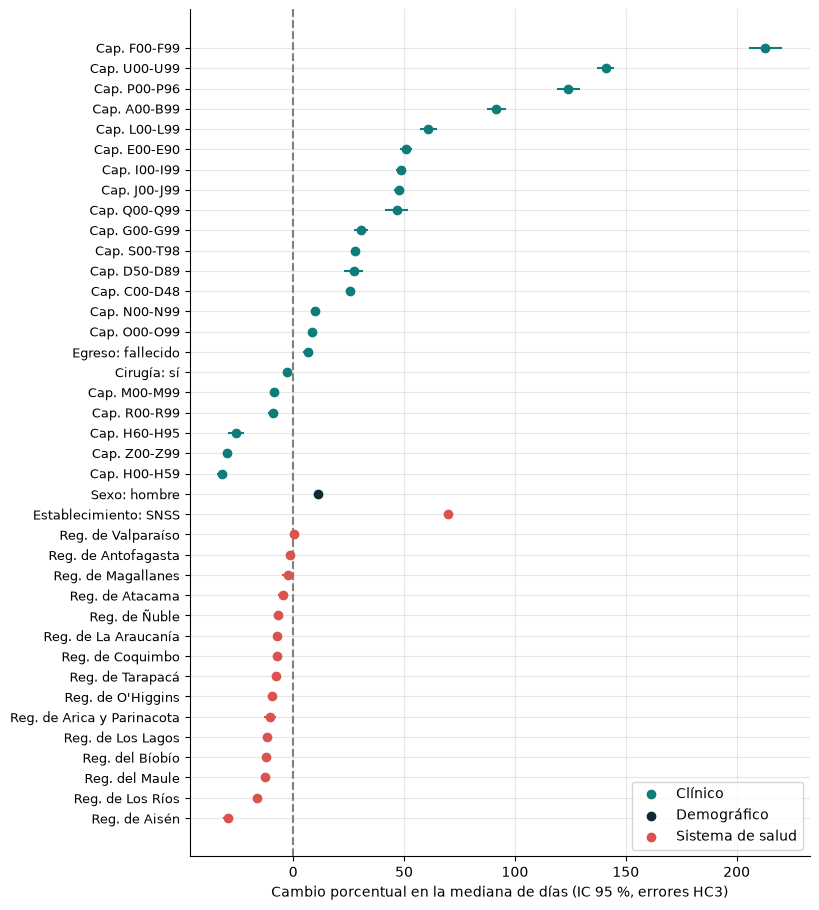

In [17]:
dibujo = coef.drop(["Intercept", "edad_c", "I(edad_c ** 2)"]).copy()
dibujo["bloque"] = np.where(dibujo.index.str.startswith(("capitulo", "cirugia", "fallecido")), "Clínico",
                    np.where(dibujo.index.str.startswith("sexo"), "Demográfico", "Sistema de salud"))
colores = {"Clínico": teal, "Demográfico": petroleo, "Sistema de salud": coral}
dibujo = dibujo.sort_values(["bloque", "%Δ"], ascending=[False, True])

fig, ax = plt.subplots(figsize=(8, 11))
for y, (nombre, fila) in enumerate(dibujo.iterrows()):
    ax.plot([fila["%Δ inf"], fila["%Δ sup"]], [y, y], color=colores[fila["bloque"]])
    ax.scatter(fila["%Δ"], y, color=colores[fila["bloque"]], zorder=3)
ax.axvline(0, color="gray", linestyle="--")
etiquetas = (dibujo.index
    .str.replace("capitulo: ", "Cap. ", regex=False)
    .str.replace("region: De Aisén del Gral. C. Ibáñez del Campo", "Reg. de Aisén", regex=False)
    .str.replace("region: De Magallanes y de La Antártica Chilena", "Reg. de Magallanes", regex=False)
    .str.replace("region: Del Libertador B. O'Higgins", "Reg. de O'Higgins", regex=False)
    .str.replace("region: De La Araucanía", "Reg. de La Araucanía", regex=False)
    .str.replace("region: De ", "Reg. de ", regex=False)
    .str.replace("region: Del ", "Reg. del ", regex=False)
    .str.replace("establecimiento: SNSS", "Establecimiento: SNSS", regex=False)
    .str.replace("sexo: HOMBRE", "Sexo: hombre", regex=False)
    .str.replace("fallecido: Sí", "Egreso: fallecido", regex=False)
    .str.replace("cirugia: Sí", "Cirugía: sí", regex=False))
ax.set_yticks(range(len(dibujo)), etiquetas, fontsize=9)
ax.set_xlabel("Cambio porcentual en la mediana de días (IC 95 %, errores HC3)")
for bloque, c in colores.items():
    ax.scatter([], [], color=c, label=bloque)
ax.legend(loc="lower right")
fig.savefig("figures/avance2_forest.png", dpi=200, bbox_inches="tight")
plt.show()


Los intervalos son tan angostos que casi no se ven, salvo en los capítulos con pocos egresos. La figura compara tamaños de %Δ: dentro del bloque clínico el capítulo tiene los %Δ más grandes, y entre los demás factores el establecimiento SNSS (+69,7 %) queda muy por sobre sexo, cirugía, condición de egreso y casi todas las regiones. Por f² parcial (3.2) el orden es capítulo (0,0798), establecimiento (0,0424) y edad (0,0365), y los otros cuatro factores quedan bajo 0,02. Para la planificación de camas, esto sugiere que el diagnóstico, el tipo de establecimiento y la edad son los factores que más se asocian con cuántos días ocupa un egreso, los tres con efecto pequeño según Cohen.

**Figura 5.** Media observada de ln(días) por tramo de edad (línea verde azulado) y media predicha por M3 en los mismos egresos (línea coral), en los datos de entrenamiento.

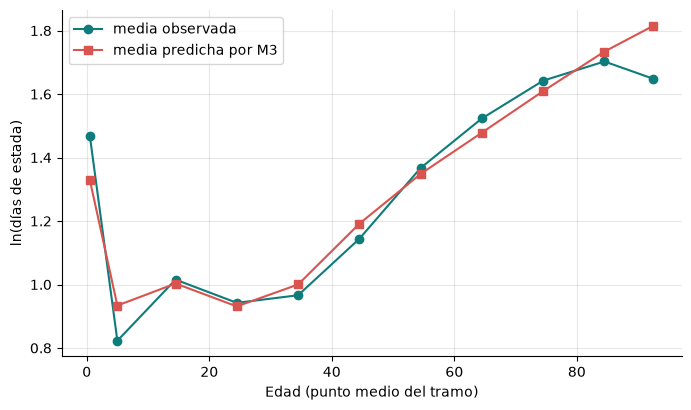

edad      0.5   5.0   14.5  24.5  34.5  44.5  54.5  64.5  74.5  84.5  92.5
log_dias  1.47  0.82  1.02  0.94  0.97  1.14  1.37  1.52  1.64  1.70  1.65
pred      1.33  0.93  1.00  0.93  1.00  1.19  1.35  1.48  1.61  1.73  1.82


In [18]:
train["pred"] = m3.fittedvalues
por_tramo = train.groupby("edad")[["log_dias", "pred"]].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(por_tramo.index, por_tramo["log_dias"], marker="o", color=teal, label="media observada")
ax.plot(por_tramo.index, por_tramo["pred"], marker="s", color=coral, label="media predicha por M3")
ax.set_xlabel("Edad (punto medio del tramo)")
ax.set_ylabel("ln(días de estada)")
ax.legend()
fig.savefig("figures/avance2_edad.png", dpi=200, bbox_inches="tight")
plt.show()
print(por_tramo.round(2).T.to_string())


El modelo sigue bien la subida desde los 20 años: de 0,93 a 1,82 en la predicción y de 0,94 a 1,65 en lo observado entre los 24,5 y los 92,5 años. Falla en los extremos. En los menores de un año predice 1,33 y lo observado es 1,47; entre 1 y 9 años predice 0,93 y lo observado es 0,82. Lo observado sigue teniendo forma de U: ln(días) medio de 1,47 en menores de un año, entre 0,82 y 1,02 entre 1 y 39 años y 1,70 en el tramo de 80 a 89 años. En el Avance 1 la edad tenía forma de U de a pares (15,4 % de prolongadas en menores de un año, 3,5 % entre 20 y 29 años y 15,4 % entre 70 y 79; la mediana de días era 4 en menores de un año contra 2 en adultos jóvenes) y por eso incluimos edad². Pero el término cuadrático estimado es casi 0 (edad² ≈ 0) y la curva ajustada queda casi recta: lo que el modelo no capta es la parábola, y por eso no reproduce el alza de los menores de un año. Una posible explicación, que no probamos, es que en el modelo conjunto el capítulo (P00-P96, el perinatal, que concentra a los menores de un año) absorbe buena parte del alza de los lactantes, y la parábola no capta lo que queda. Es una limitación del término cuadrático que elegimos en el Avance 1, y en este avance no agregamos otros modelos. Tampoco recoge que sobre los 80 años lo observado se aplana (1,70 y 1,65) mientras el modelo sigue subiendo (1,73 y 1,82). Con los tramos que trae la base no podemos distinguir mejor, y queda como limitación.

### 3.4 Evaluación en el conjunto de test

Con los coeficientes de entrenamiento predecimos el 30 % de test. Para volver a días hay que corregir: exp(ŷ) estima la mediana, no la media, porque E[exp(ε)] > 1. Usamos el estimador de Duan (1983), α = promedio de exp(residuo) en entrenamiento, y predecimos α·exp(ŷ). La línea base es predecir siempre el mismo valor: la media de entrenamiento para el RMSE y la mediana de entrenamiento para el MAE, que son los valores que minimizan cada métrica.

In [19]:
alfa = np.exp(m3.resid).mean()                    # factor de Duan, con los residuos de train
test["pred"] = m3.predict(test)
k = int(m3.df_model) + 1
for d in (train, test):
    d["pred_dias"] = alfa * np.exp(d["pred"])
    d["pred_ingenua"] = np.exp(d["pred"])

filas = []
for nombre, d in [("train", train), ("test", test)]:
    e, ed = d["log_dias"] - d["pred"], d["dias_estada"] - d["pred_dias"]
    r2 = 1 - (e ** 2).sum() / ((d["log_dias"] - d["log_dias"].mean()) ** 2).sum()
    filas.append({"conjunto": nombre, "R²": r2, "R² aj.": 1 - (1 - r2) * (len(d) - 1) / (len(d) - k),
                  "MAE ln": e.abs().mean(), "RMSE ln": np.sqrt((e ** 2).mean()),
                  "MAE días": ed.abs().mean(), "RMSE días": np.sqrt((ed ** 2).mean())})
filas.append({"conjunto": "línea base en test",
              "MAE ln": (test["log_dias"] - train["log_dias"].median()).abs().mean(),        # la mediana minimiza el MAE
              "RMSE ln": np.sqrt(((test["log_dias"] - train["log_dias"].mean()) ** 2).mean()),  # la media minimiza el RMSE
              "MAE días": (test["dias_estada"] - train["dias_estada"].median()).abs().mean(),
              "RMSE días": np.sqrt(((test["dias_estada"] - train["dias_estada"].mean()) ** 2).mean())})
metricas = pd.DataFrame(filas).set_index("conjunto")
print("α de Duan:", round(alfa, 4), "| mediana de train:", train["dias_estada"].median(), "| media de train:", round(train["dias_estada"].mean(), 3))
print("Media del perfil de referencia, α·exp(β0):", round(alfa * np.exp(coef.loc["Intercept", "β"]), 2), "días | su mediana, exp(β0):", round(np.exp(coef.loc["Intercept", "β"]), 2), "días")
print("MAE en días en test sin el factor de Duan:", round((test["dias_estada"] - test["pred_ingenua"]).abs().mean(), 3))
metricas.round(3)


α de Duan: 1.674 | mediana de train: 3.0 | media de train: 6.705
Media del perfil de referencia, α·exp(β0): 3.05 días | su mediana, exp(β0): 1.82 días
MAE en días en test sin el factor de Duan: 4.669


,R²,R² aj.,MAE ln,RMSE ln,MAE días,RMSE días
conjunto,,,,,,
train,0.198,0.198,0.727,0.927,5.366,12.347
test,0.198,0.198,0.727,0.927,5.360,12.231
línea base en test,NaN,NaN,0.828,1.035,5.025,12.714


Con α, la media del perfil de referencia es α·e^β₀ = 3,05 días, contra su mediana de 1,82 días: por eso el intercepto no es la estadía esperada. En ln(días) el modelo mejora a la línea base: R² ajustado de 0,198 en test, MAE de 0,727 contra 0,828 y RMSE de 0,927 contra 1,035. Entrenamiento y test son prácticamente iguales (R² ajustado 0,198 en ambos; RMSE en ln de 0,927 en los dos), así que no hay sobreajuste.

En días el RMSE mejora, de 12,71 a 12,23 (un 3,8 % menos). El MAE, en cambio, es peor que la línea base: 5,36 contra 5,03 de predecir siempre la mediana (3 días). Eso no hace malo al modelo. El factor de Duan corrige la media, que es lo que mide el RMSE y lo que sirve para planificar los días-cama totales, y la mediana es la que minimiza el MAE. Sin Duan, exp(ŷ) se acerca a la mediana condicional, que es lo que premia el MAE, y el MAE en test baja a 4,67, mejor que la línea base. Entonces el modelo sí mejora a la mediana cuando se le pide una predicción de mediana, y cuando se le pide la media mejora el RMSE pero no el MAE. No elegimos el predictor mirando la métrica: aplicamos Duan porque el objetivo es estimar la media de los días, y el MAE lo informamos tal como sale. Para planificar camas, donde importa el total de días-cama, la media es lo relevante.

El R² de 0,198 corresponde a un f² de 0,2471, un efecto mediano según Cohen (1988), y en días el error sigue siendo grande: un RMSE de 12 días sobre una media de 6,7. Una parte importante de la duración de un egreso no se explica con estos 7 factores.

### 3.5 Corrección de Duan y calibración

Comparamos la media real de los días con la que da exp(ŷ) y con la que da α·exp(ŷ):

In [20]:
filas = []
for nombre, d in [("train", train), ("test", test)]:
    real, ingenua, duan = d["dias_estada"].mean(), d["pred_ingenua"].mean(), d["pred_dias"].mean()
    filas.append({"conjunto": nombre, "media real": real, "media exp(ŷ)": ingenua, "media α·exp(ŷ)": duan,
                  "sesgo exp(ŷ) %": 100 * (ingenua / real - 1), "sesgo Duan %": 100 * (duan / real - 1)})
tabla_duan = pd.DataFrame(filas).set_index("conjunto")
tabla_duan.round(3)


,media real,media exp(ŷ),media α·exp(ŷ),sesgo exp(ŷ) %,sesgo Duan %
conjunto,,,,,
train,6.705,3.897,6.523,-41.887,-2.717
test,6.686,3.898,6.526,-41.697,-2.398


Con α = 1,674 la corrección es necesaria: exp(ŷ) sin corregir subestima la media de días en un 41,9 % en entrenamiento y en un 41,7 % en test. Con Duan el sesgo baja a −2,7 % y −2,4 %. Un −2,4 % residual es bajo pero no es 0, porque Duan usa un α único para todos los egresos y la varianza de los residuos crece con el valor ajustado (lo vemos en 3.6), de modo que α corrige de menos a los egresos que ya se predicen largos.

**Figura 6.** Calibración en test: promedio de días predichos y observados en cada decil de la predicción.

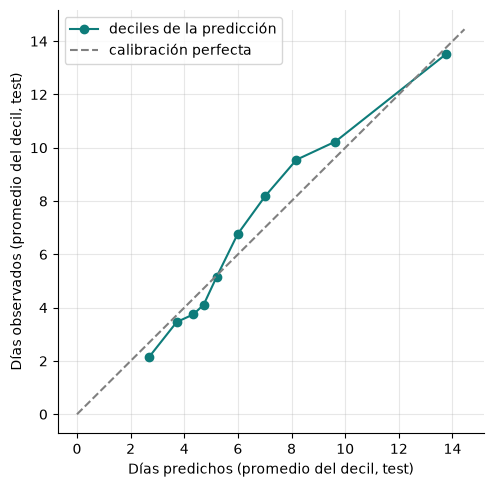

decil           0     1     2     3     4     5     6     7      8      9
pred_dias    2.69  3.72  4.34  4.72  5.21  5.99  7.02  8.18   9.64  13.76
dias_estada  2.15  3.46  3.75  4.11  5.15  6.75  8.18  9.55  10.23  13.51


In [21]:
test["decil"] = pd.qcut(test["pred_dias"].rank(method="first"), 10, labels=False)
cal = test.groupby("decil")[["pred_dias", "dias_estada"]].mean()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(cal["pred_dias"], cal["dias_estada"], marker="o", color=teal, label="deciles de la predicción")
lim = [0, max(cal.max()) * 1.05]
ax.plot(lim, lim, color="gray", linestyle="--", label="calibración perfecta")
ax.set_xlabel("Días predichos (promedio del decil, test)")
ax.set_ylabel("Días observados (promedio del decil, test)")
ax.legend()
fig.savefig("figures/avance2_calibracion.png", dpi=200, bbox_inches="tight")
plt.show()
print(cal.round(2).T.to_string())


Los puntos siguen la diagonal, así que el modelo ordena bien los egresos de menor a mayor duración. Pero hay desvíos: en el decil más bajo predice 2,69 días y lo observado es 2,15 (sobreestima), y en los deciles 6 al 9 (contando desde 1) predice menos de lo observado (por ejemplo 7,02 contra 8,18 y 8,18 contra 9,55). El último decil queda bien (13,76 contra 13,51). Por eso el modelo sirve para distinguir grupos de egresos, pero no para predecir con precisión la duración de un egreso en particular.

### 3.6 Supuestos del modelo

Revisamos los supuestos del estimador de mínimos cuadrados ordinarios (EMCO) que presenta el curso (Rodríguez y González, 2017). Los cinco primeros hacen que el estimador sea lineal, insesgado y de mínima varianza (Gauss-Markov), y el sexto, que los errores sean normales, solo se necesita para la inferencia exacta con muestras pequeñas.

| Supuesto | Qué revisamos |
|---|---|
| 1. Linealidad | Residuos contra valores ajustados (figura 7) |
| 2. Rango completo de X (sin multicolinealidad) | Rango de la matriz de diseño y VIF |
| 3. Esperanza condicional nula | Propiedad del EMCO según el material del curso (RLM): no se verifica. Con intercepto, la media de los residuos es 0 por construcción |
| 4. Perturbaciones esféricas (varianza constante y sin autocorrelación) | Breusch-Pagan (varianza); independencia, discutida más abajo |
| 5. Variables explicativas no aleatorias | No se verifica con los datos |
| 6. Normalidad de los errores | Histograma y gráfico Q-Q de los residuos (figura 7) |

El VIF y el test de Breusch-Pagan los calculamos sobre una muestra aleatoria de 30.000 egresos de entrenamiento, porque con los 677.669 son muy lentos.

In [22]:
X, r = m3.model.exog, m3.resid.values
pos = np.random.default_rng(1).choice(len(r), 30000, replace=False)     # muestra de 30.000 para VIF y Breusch-Pagan
print("Rango de X:", np.linalg.matrix_rank(X), "de", X.shape[1], "columnas")
vif = pd.Series([variance_inflation_factor(X[pos], i) for i in range(1, X.shape[1])], index=m3.model.exog_names[1:])
print("VIF máximo:", round(vif.max(), 2), "en", vif.idxmax())
print("Media de los residuos:", round(r.mean(), 6))
lm, lm_p, f_bp, f_bp_p = het_breuschpagan(r[pos], X[pos])
print("Breusch-Pagan (muestra de 30.000): LM =", round(lm, 1), "| valor-p =", lm_p)
cuartil = pd.qcut(m3.fittedvalues.rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("Desviación estándar de los residuos por cuartil de ajustados:", m3.resid.groupby(cuartil, observed=True).std().round(3).to_dict())
print("Asimetría de los residuos:", round(stats.skew(r), 3), "| curtosis en exceso:", round(stats.kurtosis(r), 3))


Rango de X: 42 de 42 columnas


VIF máximo: 2.39 en C(capitulo, Treatment('K00-K93'))[T.O00-O99]
Media de los residuos: 0.0
Breusch-Pagan (muestra de 30.000): LM = 2180.5 | valor-p = 0.0
Desviación estándar de los residuos por cuartil de ajustados: {'Q1': 0.713, 'Q2': 0.848, 'Q3': 1.038, 'Q4': 1.061}
Asimetría de los residuos: 0.493 | curtosis en exceso: 0.544


- Rango completo: la matriz de diseño tiene rango 42, igual a su número de columnas, y el VIF máximo es 2,39 (muy por debajo de 10). No hay multicolinealidad, consistente con la V de 0,43 (mediana según Cohen) de la etapa 5.
- Esperanza condicional nula: es una propiedad del EMCO según el material del curso (RLM) y no se verifica con los datos. Que la media de los residuos dé 0 es una identidad algebraica del ajuste con intercepto, no una prueba de este supuesto.
- Varianza constante: Breusch-Pagan da LM = 2.180,5 con p < 0,001 y rechaza homocedasticidad. La desviación estándar de los residuos sube de 0,713 en el primer cuartil de los valores ajustados a 1,061 en el último. Con errores heterocedásticos los coeficientes siguen siendo insesgados, pero los errores estándar clásicos no son confiables, y por eso usamos HC3 (MacKinnon y White, 1985). El test de Breusch-Pagan (1979) con 30.000 egresos tiene mucho poder, pero la diferencia entre cuartiles es de un 50 %, grande en la práctica.
- Independencia: no usamos Durbin-Watson, porque ese test supone observaciones ordenadas en el tiempo y la base no trae fechas. Aquí la limitación es que la unidad es el egreso y no el paciente, y los reingresos de un mismo paciente no son independientes. Es la limitación que ya dijimos en el Avance 1 y los errores estándar, incluso HC3, son algo optimistas por esa causa.
- Explicativas no aleatorias: se asume. Edad, sexo y diagnóstico no los fija quien diseña el estudio, pero el modelo es condicional a sus valores.
- Normalidad: la asimetría de los residuos es 0,493 y la curtosis en exceso 0,544.

**Figura 7.** Residuos contra valores ajustados de ln(días) (izquierda), histograma de los residuos (centro) y gráfico Q-Q (derecha).

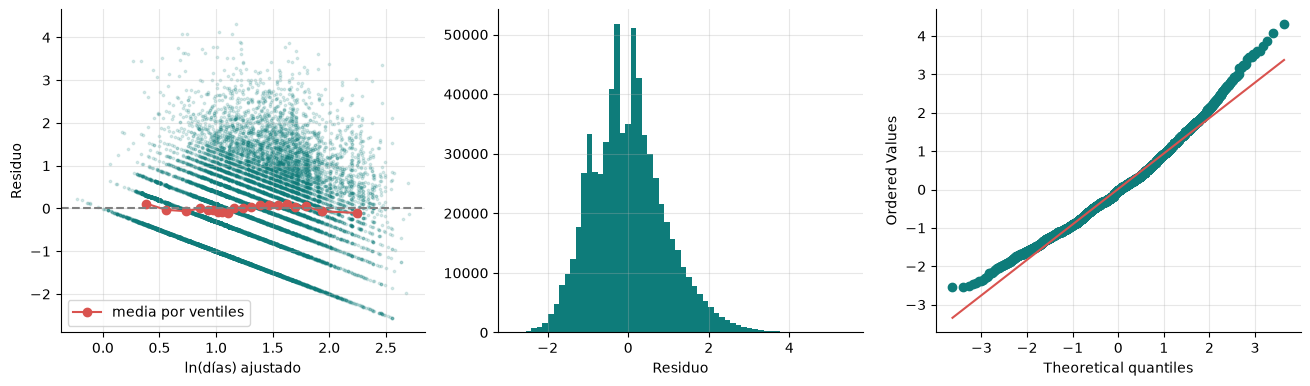

In [23]:
dec = pd.qcut(m3.fittedvalues.rank(method="first"), 20, labels=False)
medias = pd.DataFrame({"ajustado": m3.fittedvalues, "residuo": m3.resid}).groupby(dec).mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(m3.fittedvalues.values[pos[:20000]], r[pos[:20000]], s=3, alpha=0.15, color=teal)
ax[0].plot(medias["ajustado"], medias["residuo"], color=coral, marker="o", label="media por ventiles")
ax[0].axhline(0, color="gray", linestyle="--")
ax[0].set_xlabel("ln(días) ajustado")
ax[0].set_ylabel("Residuo")
ax[0].legend()
ax[1].hist(r, bins=60, color=teal)
ax[1].set_xlabel("Residuo")
stats.probplot(r[pos[:5000]], plot=ax[2])
ax[2].set_title("")
ax[2].get_lines()[0].set_color(teal)
ax[2].get_lines()[1].set_color(coral)
fig.savefig("figures/avance2_residuos.png", dpi=200, bbox_inches="tight")
plt.show()


En el gráfico de la izquierda, la media de los residuos (línea roja) se queda cerca de 0 en todo el rango de valores ajustados, así que la linealidad es razonable, con pequeñas desviaciones en los extremos. Las líneas diagonales que se ven son consecuencia de que los días son enteros: para un valor ajustado dado, un egreso de 1 día tiene siempre el mismo residuo, uno de 2 días otro, y así. La nube también se abre hacia la derecha en la parte superior, que es la heterocedasticidad con asimetría hacia arriba. El histograma tiene una cola derecha más larga y el Q-Q se separa de la recta en los extremos, sobre todo arriba. Los residuos no son normales, pero con 677.669 egresos la inferencia sobre los coeficientes se apoya en el teorema central del límite, y Gauss-Markov no necesita normalidad.

### 3.7 Avance 1 contra Avance 2

La tabla compara la asociación de cada factor en el Avance 1 (de a pares, con los valores del Avance 1) y en el modelo conjunto M3. La columna del Avance 2 se arma desde los resultados de M3.

In [24]:
d74 = 74.5 - edad_prom
pct_edad = 100 * (np.exp(coef.loc["edad_c", "β"] * d74 + coef.loc["I(edad_c ** 2)", "β"] * d74 ** 2) - 1)
pct_cap = coef.loc[en_cap, "%Δ"]
w_cap, w_reg = wald.loc["capitulo"], wald.loc["region"]
print("Edad a los 74,5 años frente a la edad media: %Δ =", round(pct_edad, 1), "%")
def es(x, d=1, signo=False):                      # número con coma decimal y punto de miles
    return f"{x:{'+' if signo else ''},.{d}f}".translate(str.maketrans(",.-", ".,−"))
fmt = lambda nombre: f"{es(coef.loc[nombre, '%Δ'], 1, True)} % [{es(coef.loc[nombre, '%Δ inf'], 1, True)}; {es(coef.loc[nombre, '%Δ sup'], 1, True)}]"
filas = [
    ("Establecimiento (SNSS)", "r = −0,37: el SNSS tiene más días", fmt("establecimiento: SNSS"), "Sigue asociado con más días después de controlar por diagnóstico, edad y región; relevante"),
    ("Capítulo CIE-10", "ε² = 0,12; V = 0,25", f"F = {es(w_cap['F (Wald/gl)'], 0)} (gl = {w_cap['df_constraint']:.0f}); %Δ de {es(pct_cap.min(), 1, True)} a {es(pct_cap.max(), 1, True)} % vs. K00-K93", "Sigue siendo el factor con mayor f²; relevante"),
    ("Sexo (hombre vs. mujer)", "r = 0,14: los hombres tienen más días", fmt("sexo: HOMBRE"), "Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el f² queda bajo 0,02: significativo, no relevante"),
    ("Edad", "ρ = 0,25: a más edad, más días", f"{es(pct_edad, 1, True)} % a los 74,5 años vs. la edad media", "Sigue subiendo con la edad, con la curva ajustada casi recta; relevante. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida"),
    ("Cirugía (sí)", "r = 0,22: los no operados tienen más días (mediana 4 contra 2)", fmt("cirugia: Sí"), "Misma dirección (los operados tienen menos días que los no operados), pero el f² queda bajo 0,02: no relevante. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43)"),
    ("Fallecido (sí)", "r = −0,29: los fallecidos tienen más días", fmt("fallecido: Sí"), "De a pares tenía más días; con el resto controlado el f² queda bajo 0,02: no relevante. Posiblemente buena parte se asocia con diagnóstico y edad"),
    ("Región", "ε² = 0,002", f"F = {es(w_reg['F (Wald/gl)'], 1)} (gl = {w_reg['df_constraint']:.0f}); %Δ de {es(coef.loc[en_reg, '%Δ'].min(), 1, True)} a {es(coef.loc[en_reg, '%Δ'].max(), 1, True)} % vs. Santiago", "De a pares casi no se veía y al controlar el f² sigue bajo 0,02: significativa como conjunto, no relevante. Aisén es la más baja"),
]
f2p = {"Establecimiento (SNSS)": "establecimiento", "Capítulo CIE-10": "capítulo", "Sexo (hombre vs. mujer)": "sexo", "Edad": "edad (edad y edad²)",
       "Cirugía (sí)": "cirugía", "Fallecido (sí)": "fallecido", "Región": "región"}
f2txt = lambda nombre: f"{es(parciales.loc[f2p[nombre], 'f² parcial'], 4)} ({parciales.loc[f2p[nombre], 'efecto (Cohen)']})"
tabla = "| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la mediana [IC 95 %]) | f² parcial (Cohen) | Qué cambia |\n|---|---|---|---|---|\n"
tabla += "\n".join(f"| {a} | {b} | {c} | {f2txt(a)} | {d} |" for a, b, c, d in filas)
display(Markdown(tabla))


Edad a los 74,5 años frente a la edad media: %Δ = 31.5 %


| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la mediana [IC 95 %]) | f² parcial (Cohen) | Qué cambia |
|---|---|---|---|---|
| Establecimiento (SNSS) | r = −0,37: el SNSS tiene más días | +69,7 % [+68,7; +70,6] | 0,0424 (pequeño) | Sigue asociado con más días después de controlar por diagnóstico, edad y región; relevante |
| Capítulo CIE-10 | ε² = 0,12; V = 0,25 | F = 2.180 (gl = 20); %Δ de −32,1 a +213,0 % vs. K00-K93 | 0,0798 (pequeño) | Sigue siendo el factor con mayor f²; relevante |
| Sexo (hombre vs. mujer) | r = 0,14: los hombres tienen más días | +11,4 % [+10,8; +12,0] | 0,0026 (menor que pequeño) | Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el f² queda bajo 0,02: significativo, no relevante |
| Edad | ρ = 0,25: a más edad, más días | +31,5 % a los 74,5 años vs. la edad media | 0,0365 (pequeño) | Sigue subiendo con la edad, con la curva ajustada casi recta; relevante. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida |
| Cirugía (sí) | r = 0,22: los no operados tienen más días (mediana 4 contra 2) | −2,7 % [−3,2; −2,2] | 0,0002 (menor que pequeño) | Misma dirección (los operados tienen menos días que los no operados), pero el f² queda bajo 0,02: no relevante. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43) |
| Fallecido (sí) | r = −0,29: los fallecidos tienen más días | +6,5 % [+4,7; +8,2] | 0,0002 (menor que pequeño) | De a pares tenía más días; con el resto controlado el f² queda bajo 0,02: no relevante. Posiblemente buena parte se asocia con diagnóstico y edad |
| Región | ε² = 0,002 | F = 215,2 (gl = 15); %Δ de −29,5 a +0,2 % vs. Santiago | 0,0048 (menor que pequeño) | De a pares casi no se veía y al controlar el f² sigue bajo 0,02: significativa como conjunto, no relevante. Aisén es la más baja |

Las cifras del Avance 1 y las del Avance 2 no son comparables en magnitud, porque miden cosas distintas (tamaño de efecto de a pares contra cambio porcentual con los otros factores controlados). Sí son comparables en dirección y en el orden de los factores (en el Avance 2, por f² parcial). Esto vale también para la edad: el efecto pequeño del Avance 1 (ρ = 0,25) es una correlación de rangos de a pares, y el +31,5 % a los 74,5 años es un cambio porcentual ajustado entre dos edades. No son la misma medida, así que no se contradicen. Con el signo pasa algo parecido: en el Avance 1 depende del orden de los grupos, y por eso la tabla dice en palabras qué grupo tiene más días. En cirugía, r = +0,22 significa que los no operados tienen más días, y el −2,7 % del modelo (operados con menos días) va en la misma dirección. Ahí cambian dos cosas. Cirugía y condición de egreso se achican en el modelo conjunto. Probablemente comparten información con el capítulo y con la edad, porque los egresos quirúrgicos y los fallecidos se concentran en ciertos diagnósticos y edades (no lo probamos). Y la región sigue sin llegar al umbral de pequeño (f² parcial 0,0048), aunque es significativa.

## 4. Discusión y conclusiones

### 4.1 Hallazgos

1. El capítulo es el factor con mayor f² parcial (0,0798, pequeño según Cohen). Entre capítulos, el cambio porcentual en la mediana va de −32 % a +213 % respecto de K00-K93, y el bloque clínico solo lleva el R² ajustado de 0 a 0,132 (f² = 0,1526, mediano).
2. El establecimiento es el segundo factor por f² parcial (0,0424, pequeño): con el diagnóstico, la edad y la región controlados, la mediana de días de un egreso del SNSS es 69,7 % mayor que la de uno fuera del SNSS.
3. La edad es el tercer factor (f² parcial 0,0365, pequeño): la mediana sube 0,9 % por año, con una curva ajustada casi recta. Los hombres tienen una mediana 11,4 % mayor que las mujeres con el resto controlado, pero el f² del sexo (0,0026) queda bajo 0,02: es significativo y no relevante.
4. Cirugía (−2,7 %) y condición de egreso (+6,5 %) tienen un f² parcial de 0,0002 cada una, y la región de 0,0048: son significativas pero no relevantes con el criterio del Avance 1.
5. El modelo explica el 19,8 % de la variabilidad de ln(días), y esa cifra es la misma en test. Mejora el RMSE en días respecto de la media (12,23 contra 12,71). El MAE con Duan (5,36) no supera a la mediana (5,03), pero sin Duan sí (4,67): Duan corrige la media, que es lo que mide el RMSE y sirve para los días-cama totales, y la predicción sin corregir se acerca a la mediana condicional, que es lo que premia el MAE. Además deja sesgo residual de −2,4 % en test y desvíos de calibración en los deciles intermedios.

### 4.2 Relación con las hipótesis

La pregunta tiene dos partes, y cada hipótesis se responde de forma distinta según la parte:

| Hipótesis | Duración (modelo conjunto, Avance 2) | Estadía prolongada (solo de a pares, Avance 1: χ² y V de Cramér) | Lectura |
|---|---|---|---|
| H1a (clínicos) | Capítulo F = 2.180 (gl = 20; −32 % a +213 %; f² parcial 0,0798, pequeño); cirugía −2,7 % y fallecido +6,5 % (f² 0,0002 cada uno), todos con p < 0,001 | Capítulo V = 0,25 y condición de egreso V = 0,11 (pequeños); cirugía V = 0,05 (despreciable) | Duración: se cumple por el capítulo, que es relevante; cirugía y condición de egreso son significativas pero no relevantes. Prolongada: asociación de a pares, sin ajuste |
| H1b (demográficos) | Edad +0,9 % por año (f² parcial 0,0365, pequeño); hombre +11,4 % (f² 0,0026) | Tramo de edad V = 0,17 y sexo V = 0,10 (pequeños) | Duración: se cumple para la edad, que es relevante; el sexo es significativo pero no relevante. Prolongada: asociación pequeña de a pares, sin ajuste. Nacionalidad y etnia quedaron fuera por el BIC en el Avance 1, así que este modelo no las evalúa |
| H1c (sistema de salud) | SNSS +69,7 % (f² parcial 0,0424, pequeño); región F = 215 (gl = 15; −29,5 % a +0,2 %; f² 0,0048) | Establecimiento V = 0,08 (despreciable); región, despreciable | Duración: se cumple por el establecimiento, que es relevante; la región es significativa pero no relevante. Prolongada: asociación despreciable de a pares, sin ajuste |

Para la duración, el veredicto sale del modelo conjunto de este avance. Para la estadía prolongada solo tenemos las asociaciones de a pares del Avance 1, que no controlan por los demás factores: no hay ajuste multivariable para las prolongadas. Es una limitación de nuestro trabajo (el Avance 1 propuso solo la regresión lineal de ln(días) y no la logística) y queda como trabajo para el paper. Un resultado significativo con 968.098 egresos no prueba una diferencia importante, y por eso damos el tamaño y juzgamos la relevancia con el criterio del Avance 1: significativo y efecto al menos pequeño (f² ≥ 0,02; Cohen, 1988). Esto es lo mismo que recomiendan Lin et al. (2013): reportar el tamaño del efecto junto al valor-p.

### 4.3 Coherencia con la literatura

- Que el diagnóstico sea el factor más asociado con la duración coincide con la idea de los GRD, según la cual diagnóstico y procedimiento explican gran parte de los recursos que consume una hospitalización y de su duración (Fetter et al., 1980).
- Que el tipo de establecimiento y la edad sigan asociados con la duración al controlar por diagnóstico coincide con Freitas et al. (2012), que encontraron esa asociación con estadías extremas dentro de un mismo GRD en Portugal.
- Elegir una regresión es coherente con la revisión de Lequertier et al. (2021), que la identifica como el método más usado para modelar la duración. El BIC (Raftery, 1995; Schwarz, 1978) es lo que nos dejó 7 variables.
- Olivares-Tirado (2020) estudió las estadías largas de los adultos mayores en Chile. Nuestro resultado de que la duración sube con la edad va en la misma línea, aunque su estudio es solo de adultos mayores y el nuestro cubre todas las edades.
- En lo técnico, usamos el estimador de Duan (1983) para volver a días, errores HC3 (MacKinnon y White, 1985), el test de Breusch y Pagan (1979) para la varianza y los umbrales de Cohen (1988) para f².

### 4.4 Posibles explicaciones

Los datos muestran asociaciones y no permiten hablar de causas. Estas son algunas explicaciones posibles, que este estudio no prueba:

- Que los egresos del SNSS tengan una mediana de días 69,7 % mayor podría deberse a que los casos más graves o más complejos, o con menos opciones de atención en otros lugares, se concentran en la red pública. La base no trae gravedad que permita separarlo.
- Que los hombres tengan una mediana 11,4 % mayor con el capítulo controlado podría venir de diferencias en la gravedad dentro de cada capítulo o de los procedimientos; con estos datos no lo sabemos.
- Que cirugía y condición de egreso se achiquen en el modelo conjunto es consistente con que dependan del diagnóstico.

### 4.5 Sesgos y limitaciones

- La unidad es el egreso y no el paciente. Los reingresos de una misma persona no son independientes, y los valores-p y los intervalos son algo optimistas.
- La base no trae peso GRD ni medida de gravedad ni comorbilidades, y tampoco hospital ni fechas (igual que en el Avance 1). El R² de 0,198 probablemente refleja eso, y las asociaciones del establecimiento o la región pueden estar recogiendo diferencias de gravedad.
- La edad viene en tramos, y el modelo no capta bien a los menores de un año ni la meseta sobre los 80. La U que vimos de a pares en el Avance 1 sigue en lo observado (ln(días) medio de 1,47 en menores de un año, entre 0,82 y 1,02 entre 1 y 39 años y 1,70 entre 80 y 89), pero el modelo no la capta, porque edad² es casi 0 y la curva ajustada queda casi recta. Una posible explicación, que no probamos, es que el capítulo (P00-P96 concentra a los menores de un año) absorba parte del alza de los lactantes.
- No ajustamos ningún modelo multivariable para las estadías prolongadas (más de 15 días). Esa parte solo tiene los resultados de a pares del Avance 1.
- 2020 fue el primer año de la pandemia, y los resultados pueden no extenderse a otros años. Aparece el capítulo U00-U99 con +141 %, propio de ese año.
- La condición de egreso se conoce al alta, así que no sirve para predecir la duración al ingreso, y el modelo es explicativo.
- La heterocedasticidad y el sesgo residual de Duan (−2,4 %) afectan la predicción en días. Con Duan el MAE no supera a la mediana (sin Duan sí), porque Duan apunta a la media y no a la mediana.
- Excluimos las estadías de más de 365 días porque son errores de registro, igual que en el Avance 1. Los atípicos de Tukey entre 15 y 365 días los conservamos, porque son estadías reales y son el fenómeno que estudiamos.

### 4.6 Implicancias

Los resultados sugieren que, para estimar la ocupación de camas, el diagnóstico, el tipo de establecimiento y la edad son los factores que más se asocian con la duración, y los tres son relevantes con el criterio del Avance 1, con efecto pequeño (f² parcial 0,0798, 0,0424 y 0,0365). Sexo, región, cirugía y condición de egreso son significativos pero quedan bajo 0,02, así que no los consideramos relevantes. La edad suma +31,5 % de mediana a los 74,5 años respecto de la edad media; es un cambio ajustado, distinto de la correlación de rangos de a pares del Avance 1. El modelo sirve para comparar grupos de egresos y estimar promedios de días de un conjunto de egresos, y es menos confiable para un egreso individual. Un paso siguiente razonable sería agregar la gravedad (GRD) y un identificador de paciente, si estuvieran disponibles.



### Paso final: cifras para la presentación

Guardamos las cifras clave en un archivo, para usarlas después en la presentación sin volver a calcularlas.

In [25]:
def num(o):
    return o.item() if hasattr(o, "item") else str(o)

cifras = {
    "n": len(df), "n_train": len(train), "n_test": len(test), "excluidos_mas_365": int((bruta > 365).sum()),
    "descriptivos": desc.round(4).to_dict("index"), "pct_prolongadas": pct_egresos, "pct_dias_cama": pct_dias,
    "atipicos": atip.round(4).to_dict("index"), "comparacion_robustez": comp.round(4).to_dict("index"),
    "pct_diag2_nulo": pct_diag2, "cramer_max": {"par": " / ".join(pares.index[0]), "V": pares.iloc[0]},
    "balance": balance.round(4).to_dict("index"),
    "modelos": tabla_modelos.round(6).to_dict("index"), "anova": anova.round(6).to_dict("index"),
    "coef": coef.round(5).to_dict("index"), "sexo_hombre_vs_mujer": coef.loc["sexo: HOMBRE"].round(5).to_dict(), "wald": wald.round(5).to_dict("index"),
    "metricas": metricas.round(5).to_dict("index"), "alfa_duan": alfa, "duan": tabla_duan.round(5).to_dict("index"),
    "vif_max": vif.max(), "bp_lm": lm, "bp_p": lm_p, "rango_X": int(np.linalg.matrix_rank(X)),
    "asimetria_residuos": stats.skew(r), "curtosis_residuos": stats.kurtosis(r),
    "f2_bloques": bloques.set_index("comparación").round(6).to_dict("index"), "f2_parciales": parciales.round(6).to_dict("index"),
    "pct_edad_74_5": pct_edad, "media_perfil_ref": alfa * np.exp(coef.loc["Intercept", "β"]), "mediana_perfil_ref": np.exp(coef.loc["Intercept", "β"]),
    "edad_tramos": por_tramo.round(4).to_dict("index"),
    "mae_sin_duan": (test["dias_estada"] - test["pred_ingenua"]).abs().mean(),
    "sd_residuos_cuartiles": m3.resid.groupby(cuartil, observed=True).std().round(5).to_dict(),
}
os.makedirs("results", exist_ok=True)
with open("results/cifras_avance2.json", "w") as f:
    json.dump(cifras, f, default=num, ensure_ascii=False, indent=1)
print("cifras guardadas:", len(cifras), "claves")


cifras guardadas: 34 claves


## Referencias

1. Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica, 47*(5), 1287–1294. https://doi.org/10.2307/1911963
2. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
3. Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association, 78*(383), 605–610. https://doi.org/10.1080/01621459.1983.10478017
4. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
5. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, Article 265. https://doi.org/10.1186/1472-6963-12-265
6. Lequertier, V., Wang, T., Fondrevelle, J., Augusto, V., & Duclos, A. (2021). Hospital length of stay prediction methods: A systematic review. *Medical Care, 59*(10), 929–938. https://doi.org/10.1097/MLR.0000000000001596
7. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
8. MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics, 29*(3), 305–325. https://doi.org/10.1016/0304-4076(85)90016-1
9. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud. https://www.superdesalud.gob.cl/biblioteca-digital/hospitalizacion-social-en-adultos-mayores-en-el-sistema-de-salud-de-chile/
10. Raftery, A. E. (1995). Bayesian model selection in social research. *Sociological Methodology, 25*, 111–163. https://doi.org/10.2307/271063
11. Rodríguez, D. E., & González, G. J. (2017). *Principios de econometría*. Fondo Editorial ITM.
12. Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136
